# Lab-4: regressiya modellari, baholash, ANOVA, p-qiymat va chi-kvadrat

**Dataset:** Student Dropout Risk 2026 (100 000 talaba). **Nishon (bashorat qilinadigan son):** `gpa_semester_2` (2-semestr GPA).

**Vazifalar:**
1. Modelni ishlab chiqish (X, y, train/test)
2. Oddiy chiziqli va ko'p chiziqli regressiya
3. Polinomial regressiya
4. Ko'p o'zgaruvchan polinomli regressiya
5. Pipeline (konveyer)
6. Baholash: o'rtacha kvadratik xato (MSE), R²
7. Bashorat qilish va qaror qabul qilish
8. ANOVA, p-qiymat, chi-kvadrat

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("student_dropout_risk_2026.csv")
print(df.shape, " bo'sh qiymatlar:", int(df.isna().sum().sum()))

(100000, 34)  bo'sh qiymatlar: 0


## 1. Modelni ishlab chiqish

Model = ma'lumotdan o'rganib, yangi ma'lumot uchun javob topadigan formula. Qadamlar:
1. **X** (kirish/xususiyatlar) va **y** (nishon) ni ajratamiz.
2. Ma'lumotni ikkiga bo'lamiz: **train** (80%, modelni o'rgatadi) va **test** (20%, modelni "imtihon" qiladi). Modelni o'zi ko'rgan ma'lumotda baholasak, natija aldamchi bo'ladi.
3. `fit()` bilan o'rgatamiz, `predict()` bilan bashorat qilamiz, `MSE` va `R²` bilan baholaymiz.

In [3]:
y = df["gpa_semester_2"]
X_all = df.drop(columns=["gpa_semester_2"])
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=1)
print("train:", len(train_idx), " test:", len(test_idx))

def split(cols):
    return df.loc[train_idx, cols], df.loc[test_idx, cols], y.loc[train_idx], y.loc[test_idx]

results = []   # barcha modellar natijasi shu yerga yig'iladi
def record(name, model, Xtr, Xte, ytr, yte):
    results.append({"model": name,
                    "R2 train": r2_score(ytr, model.predict(Xtr)),
                    "R2 test": r2_score(yte, model.predict(Xte)),
                    "MSE train": mean_squared_error(ytr, model.predict(Xtr)),
                    "MSE test": mean_squared_error(yte, model.predict(Xte))})

train: 80000  test: 20000


## 2a. Oddiy chiziqli regressiya (bitta X)

Formula: **y = b0 + b1·x**. Bu yerda x = `attendance_rate` (davomat), y = `gpa_semester_2`. b0 — kesishma (intercept), b1 — og'ish (koeffitsiyent): davomat 1 punktga oshsa GPA o'rtacha qancha o'zgaradi.

In [4]:
cols = ["attendance_rate"]
Xtr, Xte, ytr, yte = split(cols)
lm1 = LinearRegression().fit(Xtr, ytr)
print(f"b0 (intercept) = {lm1.intercept_:.4f}")
print(f"b1 (koeffitsiyent) = {lm1.coef_[0]:.5f}")
print(f"Formula: GPA2 = {lm1.intercept_:.3f} + {lm1.coef_[0]:.4f} * davomat")
print(f"90% davomat uchun bashorat: {lm1.predict(pd.DataFrame({'attendance_rate': [90]}))[0]:.2f}")
record("1. Oddiy chiziqli (davomat)", lm1, Xtr, Xte, ytr, yte)

b0 (intercept) = 1.2874
b1 (koeffitsiyent) = 0.00923
Formula: GPA2 = 1.287 + 0.0092 * davomat
90% davomat uchun bashorat: 2.12


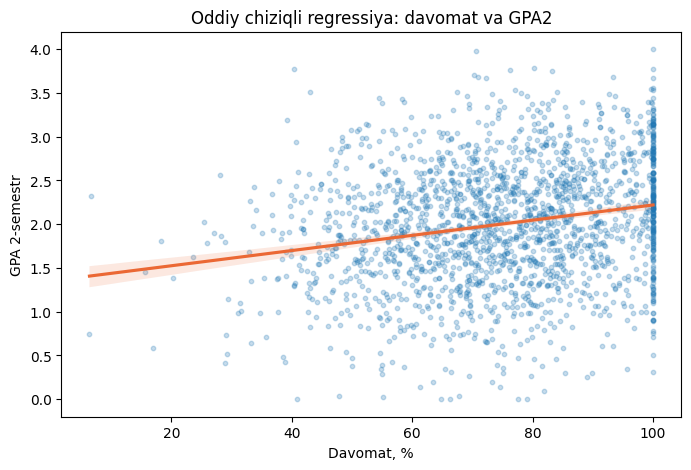

In [5]:
smp = df.sample(2000, random_state=1)
plt.figure(figsize=(8, 5))
sns.regplot(x="attendance_rate", y="gpa_semester_2", data=smp, scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "#eb6834"})
plt.title("Oddiy chiziqli regressiya: davomat va GPA2")
plt.xlabel("Davomat, %"); plt.ylabel("GPA 2-semestr")
plt.show()

## 2b. Ko'p chiziqli regressiya (bir nechta X)

**y = b0 + b1·x1 + b2·x2 + ... + bk·xk.** Har bir koeffitsiyent: boshqa X lar o'zgarmasa, shu X 1 birlikka oshganda y qancha o'zgarishi.

Xususiyatlar: oldingi semestr GPA, davomat, topshiriq ulushi, LMS kirishlari, qoldirilgan muddatlar, yiqilgan fanlar.

In [6]:
cols_m = ["gpa_semester_1", "attendance_rate", "assignments_submitted_rate", "lms_logins_per_week", "missed_deadlines", "units_failed"]
Xtr, Xte, ytr, yte = split(cols_m)
lm2 = LinearRegression().fit(Xtr, ytr)
print(f"b0 = {lm2.intercept_:.4f}")
for c, b in zip(cols_m, lm2.coef_):
    print(f"  {c:30s} b = {b:+.5f}")
record("2. Ko'p chiziqli (6 xususiyat)", lm2, Xtr, Xte, ytr, yte)

b0 = 0.0172
  gpa_semester_1                 b = +0.75529
  attendance_rate                b = +0.00025
  assignments_submitted_rate     b = +0.00010
  lms_logins_per_week            b = -0.00031
  missed_deadlines               b = +0.00022
  units_failed                   b = +0.00016


## 3. Polinomial regressiya (bitta X, egri chiziq)

Chiziq o'rniga egri: **y = b0 + b1·x + b2·x² (+ b3·x³)**. Bog'liqlik to'g'ri chiziq bo'lmasa, polinom yaxshiroq mos kelishi mumkin. Daraja oshgani sari model murakkablashadi va **overfitting** xavfi ortadi (train'da yaxshi, test'da yomon).

 daraja  R2 train  R2 test  MSE test
      1    0.6907   0.6850    0.1593
      2    0.6907   0.6851    0.1592
      3    0.6908   0.6851    0.1592
      5    0.6909   0.6851    0.1593


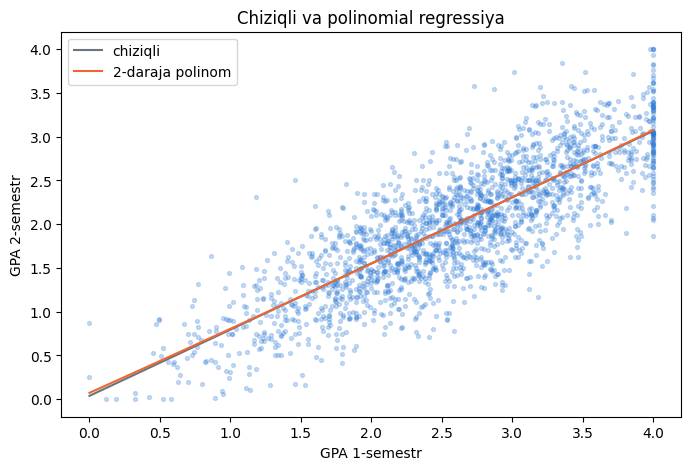

In [7]:
cols_p = ["gpa_semester_1"]
Xtr, Xte, ytr, yte = split(cols_p)
rows = []
for d in [1, 2, 3, 5]:
    coefs = np.polyfit(Xtr["gpa_semester_1"], ytr, d)
    f = np.poly1d(coefs)
    rows.append({"daraja": d, "R2 train": r2_score(ytr, f(Xtr["gpa_semester_1"])), "R2 test": r2_score(yte, f(Xte["gpa_semester_1"])),
                 "MSE test": mean_squared_error(yte, f(Xte["gpa_semester_1"]))})
poly_tbl = pd.DataFrame(rows).round(4)
print(poly_tbl.to_string(index=False))

f2 = np.poly1d(np.polyfit(Xtr["gpa_semester_1"], ytr, 2))
class _P2:
    def predict(self, X): return f2(X["gpa_semester_1"])
record("3. Polinomial, 2-daraja (GPA1)", _P2(), Xtr, Xte, ytr, yte)

s = df.sample(2000, random_state=2)
xs = np.linspace(s["gpa_semester_1"].min(), s["gpa_semester_1"].max(), 100)
plt.figure(figsize=(8, 5))
plt.scatter(s["gpa_semester_1"], s["gpa_semester_2"], s=8, alpha=0.25, color="#2a78d6")
plt.plot(xs, np.poly1d(np.polyfit(Xtr["gpa_semester_1"], ytr, 1))(xs), color="#6b7280", label="chiziqli")
plt.plot(xs, f2(xs), color="#eb6834", label="2-daraja polinom")
plt.xlabel("GPA 1-semestr"); plt.ylabel("GPA 2-semestr"); plt.legend()
plt.title("Chiziqli va polinomial regressiya")
plt.show()

## 4. Ko'p o'zgaruvchan polinomial regressiya

Bir nechta X + ularning **kvadratlari va ko'paytmalari**. Masalan, 3 ta X dan 2-darajada: x1, x2, x3, x1², x2², x3², x1·x2, x1·x3, x2·x3 (9 ta xususiyat). `PolynomialFeatures` shuni avtomatik yasaydi.

In [8]:
cols_mp = ["gpa_semester_1", "attendance_rate", "assignments_submitted_rate"]
Xtr, Xte, ytr, yte = split(cols_mp)
pf = PolynomialFeatures(degree=2, include_bias=False)
Xtr_p = pf.fit_transform(Xtr)
Xte_p = pf.transform(Xte)
print("Asl xususiyatlar:", Xtr.shape[1], "-> polinomdan keyin:", Xtr_p.shape[1])
print(pf.get_feature_names_out(cols_mp))
lm3 = LinearRegression().fit(Xtr_p, ytr)
record("4. Ko'p o'zgaruvchan polinom (3 xususiyat, 2-daraja)", lm3, Xtr_p, Xte_p, ytr, yte)

Asl xususiyatlar: 3 -> polinomdan keyin: 9
['gpa_semester_1' 'attendance_rate' 'assignments_submitted_rate'
 'gpa_semester_1^2' 'gpa_semester_1 attendance_rate'
 'gpa_semester_1 assignments_submitted_rate' 'attendance_rate^2'
 'attendance_rate assignments_submitted_rate'
 'assignments_submitted_rate^2']


## 5. Pipeline (konveyer)

Pipeline bir nechta qadamni **bitta obyektga** yig'adi: masshtablash → polinom xususiyatlar → regressiya. Foydasi: (1) kod qisqa; (2) test ma'lumotiga o'rgatish paytidagi o'sha qadamlar avtomatik qo'llanadi (xatosiz); (3) bashorat bitta `predict()` bilan.

In [9]:
pipe = Pipeline([
    ("masshtab", StandardScaler()),
    ("polinom", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressiya", LinearRegression()),
])
cols_pipe = cols_m          # 6 ta xususiyat
Xtr, Xte, ytr, yte = split(cols_pipe)
pipe.fit(Xtr, ytr)
record("5. Pipeline (6 xususiyat, 2-daraja)", pipe, Xtr, Xte, ytr, yte)
print("Pipeline qadamlari:", [name for name, _ in pipe.steps])
print("Polinomdan keyingi xususiyatlar soni:", pipe.named_steps["polinom"].n_output_features_)

Pipeline qadamlari: ['masshtab', 'polinom', 'regressiya']
Polinomdan keyingi xususiyatlar soni: 27


## 6. Baholash: MSE va R²

- **MSE** = o'rtacha( (haqiqiy − bashorat)² ). Kichikroq = yaxshiroq. Kvadrat bo'lgani uchun katta xatolarni qattiq "jazolaydi". Birligi y birligining kvadrati.
- **R²** = 1 − (xatolar yig'indisi / jami tarqoqlik). 0 dan 1 gacha (yomon modelda manfiy bo'lishi ham mumkin). R² = 0,70 degani: GPA2 o'zgarishining 70% ini model tushuntiradi.
- Asosiy baho **test** ustunlaridan olinadi.

In [10]:
# MSE va R2 ni qo'lda ham hisoblaymiz (oddiy chiziqli model, test ma'lumoti)
Xtr, Xte, ytr, yte = split(["attendance_rate"])
pred = lm1.predict(Xte)
mse_manual = ((yte - pred) ** 2).mean()
r2_manual = 1 - ((yte - pred) ** 2).sum() / ((yte - yte.mean()) ** 2).sum()
print(f"MSE qo'lda   = {mse_manual:.5f}   sklearn = {mean_squared_error(yte, pred):.5f}")
print(f"R2  qo'lda   = {r2_manual:.5f}   sklearn = {r2_score(yte, pred):.5f}")
res = pd.DataFrame(results).set_index("model").round(4)
res

MSE qo'lda   = 0.48183   sklearn = 0.48183
R2  qo'lda   = 0.04729   sklearn = 0.04729


,R2 train,R2 test,MSE train,MSE test
model,,,,
1. Oddiy chiziqli (davomat),0.0500,0.0473,0.4918,0.4818
2. Ko'p chiziqli (6 xususiyat),0.6907,0.6850,0.1601,0.1593
"3. Polinomial, 2-daraja (GPA1)",0.6907,0.6851,0.1601,0.1592
"4. Ko'p o'zgaruvchan polinom (3 xususiyat, 2-daraja)",0.6908,0.6850,0.1601,0.1593
"5. Pipeline (6 xususiyat, 2-daraja)",0.6909,0.6848,0.1600,0.1594


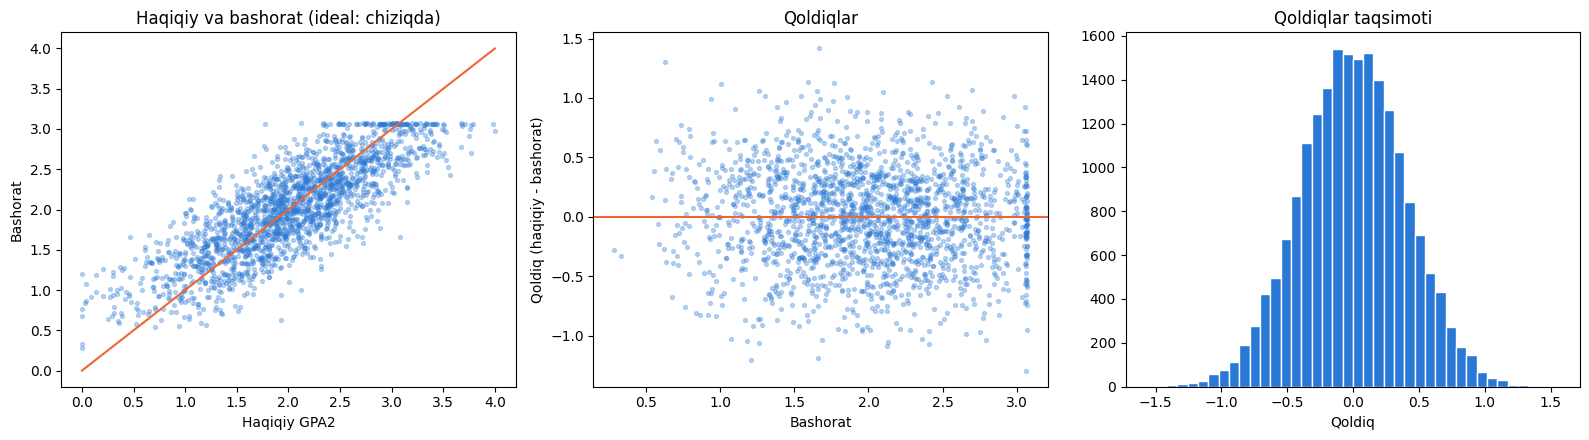

In [11]:
# Vizualizatsiya: haqiqiy va bashorat, hamda qoldiqlar (ko'p chiziqli model)
Xtr, Xte, ytr, yte = split(cols_m)
pred = lm2.predict(Xte)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(yte[:2000], pred[:2000], s=8, alpha=0.3, color="#2a78d6")
ax[0].plot([0, 4], [0, 4], color="#eb6834")
ax[0].set_xlabel("Haqiqiy GPA2"); ax[0].set_ylabel("Bashorat"); ax[0].set_title("Haqiqiy va bashorat (ideal: chiziqda)")
resid = yte - pred
ax[1].scatter(pred[:2000], resid[:2000], s=8, alpha=0.3, color="#2a78d6")
ax[1].axhline(0, color="#eb6834")
ax[1].set_xlabel("Bashorat"); ax[1].set_ylabel("Qoldiq (haqiqiy - bashorat)"); ax[1].set_title("Qoldiqlar")
ax[2].hist(resid, bins=40, color="#2a78d6", edgecolor="white")
ax[2].set_xlabel("Qoldiq"); ax[2].set_title("Qoldiqlar taqsimoti")
plt.tight_layout()
plt.show()

## 7. Bashorat qilish va qaror qabul qilish

Model faqat son chiqaradi, **qaror** esa odam qabul qiladi. Misol: bashorat qilingan GPA2 past bo'lgan talabalarni "xavf guruhi" deb belgilab, ularga qo'shimcha yordam ko'rsatish.

In [12]:
# 1) Yangi talabalar uchun bashorat
new = pd.DataFrame({
    "gpa_semester_1": [3.5, 2.0, 1.0],
    "attendance_rate": [95, 70, 40],
    "assignments_submitted_rate": [98, 70, 30],
    "lms_logins_per_week": [8, 4, 1],
    "missed_deadlines": [0, 2, 8],
    "units_failed": [0, 1, 4],
}, index=["A (yaxshi)", "B (o'rta)", "C (xavf)"])
new["bashorat GPA2"] = lm2.predict(new[cols_m]).round(2)
new

,gpa_semester_1,attendance_rate,assignments_submitted_rate,lms_logins_per_week,missed_deadlines,units_failed,bashorat GPA2
A (yaxshi),3.5,95,98,8,0,0,2.69
B (o'rta),2.0,70,70,4,2,1,1.55
C (xavf),1.0,40,30,1,8,4,0.79


In [13]:
# 2) Qaror qoidasi: bashorat GPA2 < 1.5 bo'lsa -> "xavf guruhi"
Xtr, Xte, ytr, yte = split(cols_m)
pred = pd.Series(lm2.predict(Xte), index=Xte.index)
flag = pred < 1.5
tbl = pd.DataFrame({"talabalar": [int((~flag).sum()), int(flag.sum())],
                    "haqiqiy dropout ulushi": [df.loc[pred[~flag].index, "dropout"].mean(), df.loc[pred[flag].index, "dropout"].mean()]},
                   index=["xavf emas", "xavf guruhi"]).round(3)
print(f"Test talabalarining {flag.mean() * 100:.1f}% i xavf guruhiga tushdi")
tbl

Test talabalarining 21.2% i xavf guruhiga tushdi


,talabalar,haqiqiy dropout ulushi
xavf emas,15754,0.203
xavf guruhi,4246,0.769


**Xulosa (qaror):** model dropout ni o'zi bashorat qilmaydi, lekin GPA2 past chiqadigan talabalarni ajratadi, ular orasida dropout ulushi yuqori bo'lsa, qoida foydali. Chegarani (1,5) o'zgartirsak, ko'proq/kamroq talaba belgilanadi: bu **qaror** (qancha resurs bor, qanday xatoga tayyormiz) masalasi.

## 8a. p-qiymat nima

Savol: "ko'rilgan farq tasodifmi?" **Nol gipoteza (H0):** farq yo'q. **p-qiymat** — H0 to'g'ri bo'lsa, bizdagidek yoki undan kuchliroq farq tasodifan chiqish ehtimoli.
- **p < 0,05** → farq tasodif emas deb hisoblaymiz (H0 rad etiladi).
- **p ≥ 0,05** → farq borligiga yetarli dalil yo'q.
- **p = 0 chiqsa**, bu aslida nol emas: p juda kichik (kompyuter 0 deb yaxlitlaydi), ya'ni p < 0,001 deb o'qing.
- Eslatma: 100 000 qatorda ozgina farq ham p < 0,05 beradi, shuning uchun **effekt kattaligiga** (eta², Cramér V, r) ham qarang.

## 8b. ANOVA (bir omilli dispersiya tahlili)

**Savol:** 3 va undan ortiq guruhning o'rtachasi farq qiladimi? Misol: oila daromadi (Low/Middle/High) bo'yicha GPA2.

**Formula:** F = (guruhlar orasidagi o'zgarish / (k−1)) / (guruh ichidagi o'zgarish / (N−k)). F katta bo'lsa, guruhlar o'rtasidagi farq guruh ichidagi tebranishdan katta.

In [14]:
groups = {k: g["gpa_semester_2"].values for k, g in df.groupby("family_income_level")}
print({k: round(v.mean(), 3) for k, v in groups.items()})

# Qo'lda
allv = df["gpa_semester_2"].values
N, k = len(allv), len(groups)
gm = allv.mean()
ssb = sum(len(v) * (v.mean() - gm) ** 2 for v in groups.values())     # guruhlar orasida
ssw = sum(((v - v.mean()) ** 2).sum() for v in groups.values())       # guruh ichida
F = (ssb / (k - 1)) / (ssw / (N - k))
p = stats.f.sf(F, k - 1, N - k)
print(f"\nQo'lda:  F = {F:.2f},  p = {p:.3g},  eta^2 = {ssb / (ssb + ssw):.4f}")

# scipy bilan tekshiruv
F2, p2 = stats.f_oneway(*groups.values())
print(f"scipy:   F = {F2:.2f},  p = {p2:.3g}")
print("Xulosa:", "guruhlar o'rtachasi farq qiladi (p < 0.05)" if p2 < 0.05 else "farqqa dalil yo'q (p >= 0.05)")

{'High': np.float64(2.161), 'Low': np.float64(1.829), 'Middle': np.float64(2.0)}

Qo'lda:  F = 1625.90,  p = 0,  eta^2 = 0.0315
scipy:   F = 1625.90,  p = 0
Xulosa: guruhlar o'rtachasi farq qiladi (p < 0.05)


course_type bo'yicha GPA2: F = 0.48, p = 0.748 -> farq yo'q (tasodif)


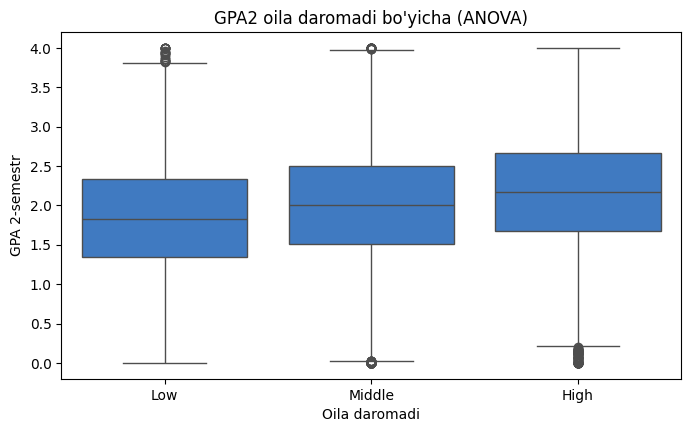

In [15]:
# Taqqoslash uchun: farq yo'q bo'lishi kutilgan omil (o'qish yo'nalishi)
g2 = [g["gpa_semester_2"].values for _, g in df.groupby("course_type")]
F3, p3 = stats.f_oneway(*g2)
print(f"course_type bo'yicha GPA2: F = {F3:.2f}, p = {p3:.3f} ->", "farq bor" if p3 < 0.05 else "farq yo'q (tasodif)")

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="family_income_level", y="gpa_semester_2", order=["Low", "Middle", "High"], color="#2a78d6")
plt.title("GPA2 oila daromadi bo'yicha (ANOVA)"); plt.xlabel("Oila daromadi"); plt.ylabel("GPA 2-semestr")
plt.show()

## 8c. Chi-kvadrat testi (kategorik va kategorik)

**Savol:** ikki kategorik o'zgaruvchi bog'liqmi? Misol: oila daromadi va dropout.

**G'oya:** agar bog'liqlik bo'lmasa, har katakda **kutilgan** son = (qator yig'indisi × ustun yig'indisi) / jami. **χ² = Σ (kuzatilgan − kutilgan)² / kutilgan**. Kuzatilgan kutilgandan qanchalik uzoq bo'lsa, χ² shunchalik katta.

In [16]:
ct = pd.crosstab(df["family_income_level"], df["dropout"])
print("Kuzatilgan:\n", ct)

# Qo'lda
exp = np.outer(ct.sum(axis=1), ct.sum(axis=0)) / ct.values.sum()
chi2_manual = ((ct.values - exp) ** 2 / exp).sum()
print("\nKutilgan:\n", pd.DataFrame(exp.round(1), index=ct.index, columns=ct.columns))
print(f"\nQo'lda chi2 = {chi2_manual:.2f}")

chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"scipy:   chi2 = {chi2:.2f},  p = {p:.3g},  erkinlik darajasi = {dof},  Cramer V = {cramers_v:.3f}")
print("Xulosa:", "daromad va dropout bog'liq (p < 0.05)" if p < 0.05 else "bog'liqlikka dalil yo'q")

Kuzatilgan:
 dropout                  0      1
family_income_level              
High                 19985   4993
Low                  19869  14940
Middle               28142  12071

Kutilgan:
 dropout                    0        1
family_income_level                  
High                 16984.0   7994.0
Low                  23668.7  11140.3
Middle               27343.2  12869.8

Qo'lda chi2 = 3635.74
scipy:   chi2 = 3635.74,  p = 0,  erkinlik darajasi = 2,  Cramer V = 0.191
Xulosa: daromad va dropout bog'liq (p < 0.05)


course_type va dropout: chi2 = 1.25, p = 0.869 -> bog'liq emas


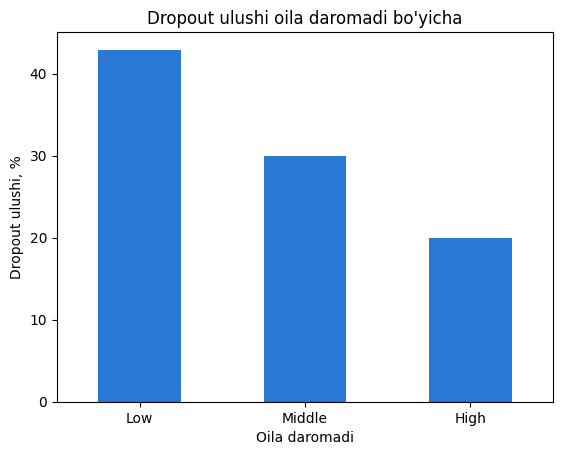

In [17]:
# Taqqoslash: o'qish yo'nalishi va dropout (bog'liqlik kutilmaydi)
ct2 = pd.crosstab(df["course_type"], df["dropout"])
chi2b, pb, dofb, _ = stats.chi2_contingency(ct2)
print(f"course_type va dropout: chi2 = {chi2b:.2f}, p = {pb:.3f} ->", "bog'liq" if pb < 0.05 else "bog'liq emas")

(ct.div(ct.sum(axis=1), axis=0)[1] * 100).reindex(["Low", "Middle", "High"]).plot(kind="bar", color="#2a78d6", rot=0)
plt.ylabel("Dropout ulushi, %"); plt.xlabel("Oila daromadi"); plt.title("Dropout ulushi oila daromadi bo'yicha")
plt.show()

## 8d. Boshqa testlar

| Test | Qachon ishlatiladi | Misol |
|---|---|---|
| **t-test** (2 guruh) | 2 guruh o'rtachasini solishtirish | ketganlar va qolganlar davomati |
| **ANOVA** | 3+ guruh o'rtachasi | daromad darajalari bo'yicha GPA |
| **Kruskal–Wallis** | ANOVA'ning normal taqsimot talab qilmaydigan varianti | og'gan ma'lumot |
| **Chi-kvadrat** | ikki kategorik o'zgaruvchi bog'liqligi | daromad va dropout |
| **Pearson korrelyatsiya testi** | ikki son o'zgaruvchi chiziqli bog'liqligi (r va p) | davomat va GPA |
| **Shapiro–Wilk** | taqsimot normalmi (≤5000 qiymatda) | GPA2 |

In [18]:
# t-test: ketganlar va qolganlar davomati
a0 = df.loc[df["dropout"] == 0, "attendance_rate"]
a1 = df.loc[df["dropout"] == 1, "attendance_rate"]
t, pt = stats.ttest_ind(a0, a1, equal_var=False)
print(f"t-test (davomat): qolgan {a0.mean():.1f} vs ketgan {a1.mean():.1f},  t = {t:.1f},  p = {pt:.3g}")

# Kruskal-Wallis: daromad bo'yicha GPA2 (ANOVA ning noparametrik varianti)
h, pk = stats.kruskal(*groups.values())
print(f"Kruskal-Wallis (GPA2 ~ daromad): H = {h:.1f}, p = {pk:.3g}")

# Pearson testi: davomat va GPA2
r, pr = stats.pearsonr(df["attendance_rate"], df["gpa_semester_2"])
print(f"Pearson (davomat, GPA2): r = {r:.3f}, p = {pr:.3g}")

# Shapiro-Wilk: GPA2 normalmi (5000 ta tasodifiy qiymatda)
w, ps = stats.shapiro(df["gpa_semester_2"].sample(5000, random_state=1))
print(f"Shapiro-Wilk (GPA2): W = {w:.4f}, p = {ps:.3g} ->", "normal emas (p < 0.05)" if ps < 0.05 else "normalga yaqin (p >= 0.05)")

t-test (davomat): qolgan 78.5 vs ketgan 67.9,  t = 91.1,  p = 0
Kruskal-Wallis (GPA2 ~ daromad): H = 3008.5, p = 0
Pearson (davomat, GPA2): r = 0.222, p = 0
Shapiro-Wilk (GPA2): W = 0.9983, p = 3.95e-05 -> normal emas (p < 0.05)


## Xulosa va loyihani boshlash

- Eng yaxshi model testda eng yuqori R² va eng past MSE bergani; murakkab model (polinom) har doim yaxshiroq emas: test natijasini train bilan solishtiring.
- Testlar: ANOVA va chi-kvadrat kategoriyalar orasidagi farq tasodif emasligini tekshiradi; katta datasetda p kichik chiqadi, shuning uchun effekt kattaligiga (η², Cramér V) ham qarang.
- **Loyiha uchun keyingi qadam:** biznes savol qo'yish (qaysi talaba dropout xavfida?), tozalash, EDA, model, dashboard.